In [7]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import fastf1

from src.solver import solve_lap, lap_time
from src.track import track_geometry
from src.params import CAR_2022, CAR_2022_FIT, RANGES_2022, G
from src.vehicle import (v_apex, critical_radius, normal_accel, a_long_tyre,
                         a_power, a_drag, a_accel, a_brake)

fastf1.Cache.enable_cache('../cache')
fastf1.set_log_level('WARNING')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


c:\Users\Ryan\Documents\f1-lapsim\.venv\Lib\site-packages\fastf1\req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "


In [2]:
session = fastf1.get_session(2022, 'Spain', 'Q')
session.load()
lap = session.laps.pick_drivers('LEC').pick_fastest()
geo = track_geometry(lap)
print(f"{lap['LapTime']}, {len(geo)} points, s = 0 to {geo['s'].iloc[-1]:.0f} m")

0 days 00:01:18.750000, 2293 points, s = 0 to 4584 m


In [3]:
# =================================
# Getting density from the weather
# =================================

weather = lap.get_weather_data()      

T_air = weather['AirTemp'] + 273.15    
p_air = weather['Pressure'] * 100      
R_air = 287.05                         

rho = p_air / (R_air * T_air)          

print(f"Air {weather['AirTemp']:.1f} °C, {weather['Pressure']:.1f} mbar, "
      f"humidity {weather['Humidity']:.0f} %")
print(f"rho = {rho:.3f} kg/m^3")

Air 34.6 °C, 1002.9 mbar, humidity 18 %
rho = 1.135 kg/m^3


In [4]:
# =================================
# Cornering limit for both sets
# =================================

sets = {'Sourced': CAR_2022, 'Identified': CAR_2022_FIT}

for name, car in sets.items():
    geo[f'v_apex_{name}'] = v_apex(geo['r'], car['m'], car['mu_y'], rho, car['ClA'])
    r_c = critical_radius(car['m'], car['mu_y'], rho, car['ClA'])
    print(f"{name:10s}  r_crit = {r_c:5.0f} m")

Sourced     r_crit =   146 m
Identified  r_crit =   144 m


In [5]:
# =================================
# Check the longitudinal limits on a straight
# =================================

car = CAR_2022
v_test = np.array([50, 100, 150, 200, 250, 300]) / 3.6
straight = np.zeros_like(v_test)          # kappa = 0 everywhere

tyre  = a_long_tyre(v_test, straight, car['m'], car['mu_x'], car['mu_y'], rho, car['ClA'])
power = a_power(v_test, car['m'], car['P_max'])
drag  = a_drag(v_test, car['m'], rho, car['CdA'])
acc   = a_accel(v_test, straight, car, rho)
brk   = a_brake(v_test, straight, car, rho)

print("  v [km/h]   tyre    power   drag  | accel   brake   [all in g]")
for i in range(len(v_test)):
    print(f"  {v_test[i]*3.6:6.0f}   {tyre[i]/G:5.2f}   {power[i]/G:5.2f}   "
          f"{drag[i]/G:5.2f} | {acc[i]/G:5.2f}   {brk[i]/G:5.2f}")

v_term = (2 * car['P_max'] / (rho * car['CdA']))**(1/3)
print(f"\nTerminal speed (power = drag): {v_term*3.6:.0f} km/h   (measured top ~318, DRS open)")

  v [km/h]   tyre    power   drag  | accel   brake   [all in g]
      50    1.73    6.09    0.02 |  1.71    1.76
     100    2.14    3.04    0.08 |  2.06    2.22
     150    2.81    2.03    0.19 |  1.84    3.00
     200    3.76    1.52    0.33 |  1.19    4.09
     250    4.97    1.22    0.52 |  0.70    5.49
     300    6.45    1.01    0.75 |  0.27    7.20

Terminal speed (power = drag): 332 km/h   (measured top ~318, DRS open)


In [ ]:
# =================================
# Consistency check with stage 3
# =================================

for name, car in sets.items():
    va = geo[f'v_apex_{name}'].to_numpy()
    kap = geo['kappa'].to_numpy()
    finite = np.isfinite(va)              # skip 'no cornering limit' points
    left = a_long_tyre(va[finite], kap[finite], car['m'], car['mu_x'],
                       car['mu_y'], rho, car['ClA'])
    print(f"{name:10s}  max a_x left at v = v_apex: {left.max():.2e} m/s^2 "
          f"over {finite.sum()} points")

Sourced     max a_x left at v = v_apex: 1.78e-04 m/s^2 over 824 points
Identified  max a_x left at v = v_apex: 4.50e-04 m/s^2 over 818 points


In [8]:
v_start = geo['v'].iloc[0]     # boundary condition
v_end = geo['v'].iloc[-1]
print(f"Boundary speeds: start {v_start*3.6:.1f} km/h, end {v_end*3.6:.1f} km/h")

res = solve_lap(geo, CAR_2022, rho, v_start, v_end)

print(f"Simulated lap (sourced): {res['t']:.3f} s")
print(f"Any nan in v?          {np.isnan(res['v']).any()}")
print(f"Max of v - v_apex:     {np.max(res['v'] - res['v_apex']):.2e} m/s (should be <= 0)")
print(f"Speed range:           {res['v'].min()*3.6:.1f} to {res['v'].max()*3.6:.1f} km/h")

Boundary speeds: start 288.2 km/h, end 285.6 km/h
Simulated lap (sourced): 80.690 s
Any nan in v?          False
Max of v - v_apex:     0.00e+00 m/s (should be <= 0)
Speed range:           71.0 to 328.3 km/h


In [9]:
# =================================
# Both sets against a like-for-like measured time
# =================================

t_meas_grid = lap_time(geo['s'].to_numpy(), geo['v'].to_numpy())
print(f"Official LEC lap:                       78.750 s")
print(f"Measured speed integrated on same grid: {t_meas_grid:.3f} s\n")

results = {}
for name, car in sets.items():
    results[name] = solve_lap(geo, car, rho, v_start, v_end)
    t = results[name]['t']
    print(f"{name:10s}  {t:7.3f} s   delta vs same-grid measured: {t - t_meas_grid:+.3f} s")

Official LEC lap:                       78.750 s
Measured speed integrated on same grid: 77.835 s

Sourced      80.690 s   delta vs same-grid measured: +2.855 s
Identified   71.930 s   delta vs same-grid measured: -5.904 s


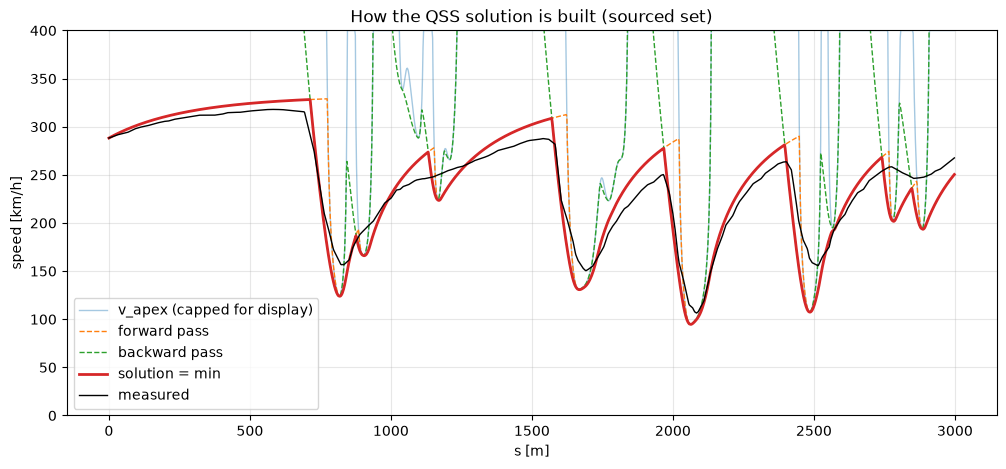

In [ ]:
# =================================
# Starting to find the brake point
# =================================

r = results['Sourced']
sl = slice(0, 1500)    # main straight into T1

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(geo['s'][sl], np.minimum(r['v_apex'][sl], 400/3.6) * 3.6, lw=1, alpha=0.4, label='v_apex (capped for display)')
ax.plot(geo['s'][sl], r['v_fwd'][sl] * 3.6, lw=1, ls='--', label='forward pass')
ax.plot(geo['s'][sl], r['v_bwd'][sl] * 3.6, lw=1, ls='--', label='backward pass')
ax.plot(geo['s'][sl], r['v'][sl] * 3.6, lw=2, label='solution = min')
ax.plot(geo['s'][sl], geo['v'][sl] * 3.6, lw=1, color='k', label='measured')
ax.set_ylim(0, 400)
ax.set_xlabel('s [m]'); ax.set_ylabel('speed [km/h]')
ax.set_title('How the QSS solution is built (sourced set)')
ax.grid(alpha=0.3); ax.legend(loc='lower left')
plt.show()

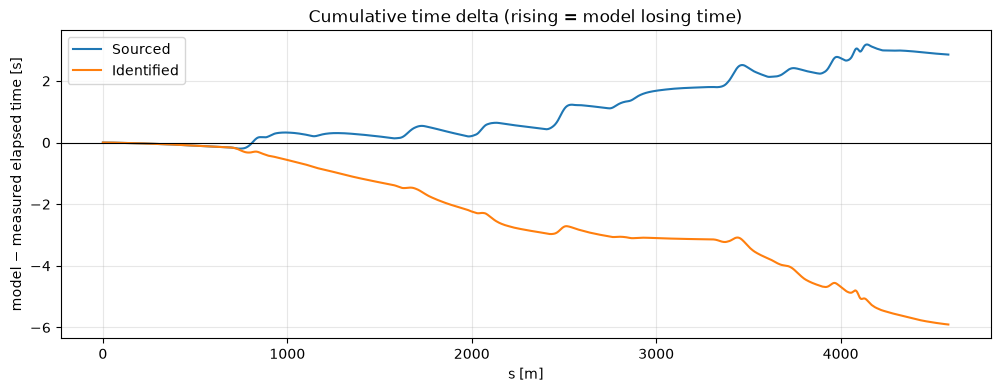

Sourced    final delta: +2.855 s
Identified final delta: -5.904 s


In [11]:
# =================================
# Cumulative time delta 
# =================================

s = geo['s'].to_numpy()
ds = np.diff(s)

def cum_time(v):
    """Elapsed time at every point [s], same quadrature as lap_time()."""
    v_mid = 0.5 * (v[:-1] + v[1:])
    return np.concatenate([[0.0], np.cumsum(ds / v_mid)])

t_meas = cum_time(geo['v'].to_numpy())

fig, ax = plt.subplots(figsize=(12, 4))
for name, res in results.items():
    ax.plot(s, cum_time(res['v']) - t_meas, lw=1.5, label=name)
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('s [m]')
ax.set_ylabel('model − measured elapsed time [s]')
ax.set_title('Cumulative time delta (rising = model losing time)')
ax.grid(alpha=0.3); ax.legend()
plt.savefig('../figures/04_time_delta.png', dpi=200)
plt.show()

for name, res in results.items():
    print(f"{name:10s} final delta: {cum_time(res['v'])[-1] - t_meas[-1]:+.3f} s")

In [12]:
# =================================
# How much of the −5.9 s is μ_x?
# =================================

hybrid = {**CAR_2022_FIT, 'mu_x': CAR_2022['mu_x']}   # DIAGNOSTIC ONLY
res_h = solve_lap(geo, hybrid, rho, v_start, v_end)
print(f"Identified lateral + sourced mu_x = 1.6: {res_h['t']:.3f} s   "
      f"delta: {res_h['t'] - t_meas_grid:+.3f} s")

Identified lateral + sourced mu_x = 1.6: 73.550 s   delta: -4.285 s


In [13]:
# =================================
# Convergence in ds 
# =================================

s0, s1 = geo['s'].iloc[0], geo['s'].iloc[-1]

def regrid(geo, ds_new):
    """Same track (same kappa(s)), different step size. Integrator test only."""
    n_pts = int(round((s1 - s0) / ds_new)) + 1
    s_new = np.linspace(s0, s1, n_pts)
    kap = np.interp(s_new, geo['s'], geo['kappa'])
    with np.errstate(divide='ignore'):
        r_new = 1.0 / np.abs(kap)
    return pd.DataFrame({'s': s_new, 'kappa': kap, 'r': r_new})

prev = None
print("  ds [m]   lap [s]    change vs previous")
for ds_try in [8.0, 4.0, 2.0, 1.0, 0.5]:
    t = solve_lap(regrid(geo, ds_try), CAR_2022, rho, v_start, v_end)['t']
    change = '' if prev is None else f"{t - prev:+.4f}"
    print(f"  {ds_try:5.1f}   {t:8.4f}   {change}")
    prev = t

  ds [m]   lap [s]    change vs previous
    8.0    81.4843   
    4.0    80.9290   -0.5554
    2.0    80.6899   -0.2390
    1.0    80.5661   -0.1238
    0.5    80.5056   -0.0605


In [14]:
# =================================
# Verstappen's Lap
# =================================

lap_ver = session.laps.pick_drivers('VER').pick_fastest()
geo_ver = track_geometry(lap_ver)

w = lap_ver.get_weather_data()
rho_ver = (w['Pressure'] * 100) / (287.05 * (w['AirTemp'] + 273.15))

v0_ver, v1_ver = geo_ver['v'].iloc[0], geo_ver['v'].iloc[-1]
t_meas_ver = lap_time(geo_ver['s'].to_numpy(), geo_ver['v'].to_numpy())

print(f"VER official: {lap_ver['LapTime'].total_seconds():.3f} s   rho = {rho_ver:.3f}")
print(f"Measured on own grid: {t_meas_ver:.3f} s\n")

results_ver = {}
for name, car in sets.items():
    results_ver[name] = solve_lap(geo_ver, car, rho_ver, v0_ver, v1_ver)
    t = results_ver[name]['t']
    print(f"{name:10s}  {t:7.3f} s   delta: {t - t_meas_ver:+.3f} s")

VER official: 79.073 s   rho = 1.136
Measured on own grid: 77.874 s

Sourced      80.473 s   delta: +2.600 s
Identified   71.893 s   delta: -5.981 s


In [15]:
# =================================
# Top speed and peak braking checked 
# against the data itself 
# =================================

def accel_profile(s, v):
    """Longitudinal acceleration from d(v^2)/ds = 2a, per segment [m/s^2]."""
    return np.diff(v**2) / (2 * np.diff(s))

a_meas = accel_profile(s, geo['v'].to_numpy())
print(f"{'':12s}  top speed   peak brake   peak accel")
print(f"{'Measured':12s}  {geo['v'].max()*3.6:6.1f} km/h   {-a_meas.min()/G:5.2f} g     {a_meas.max()/G:5.2f} g")
for name, res in results.items():
    a = accel_profile(s, res['v'])
    print(f"{name:12s}  {res['v'].max()*3.6:6.1f} km/h   {-a.min()/G:5.2f} g     {a.max()/G:5.2f} g")

              top speed   peak brake   peak accel
Measured       318.0 km/h    5.90 g      2.08 g
Sourced        328.3 km/h    7.74 g      2.28 g
Identified     328.6 km/h    8.28 g      2.58 g


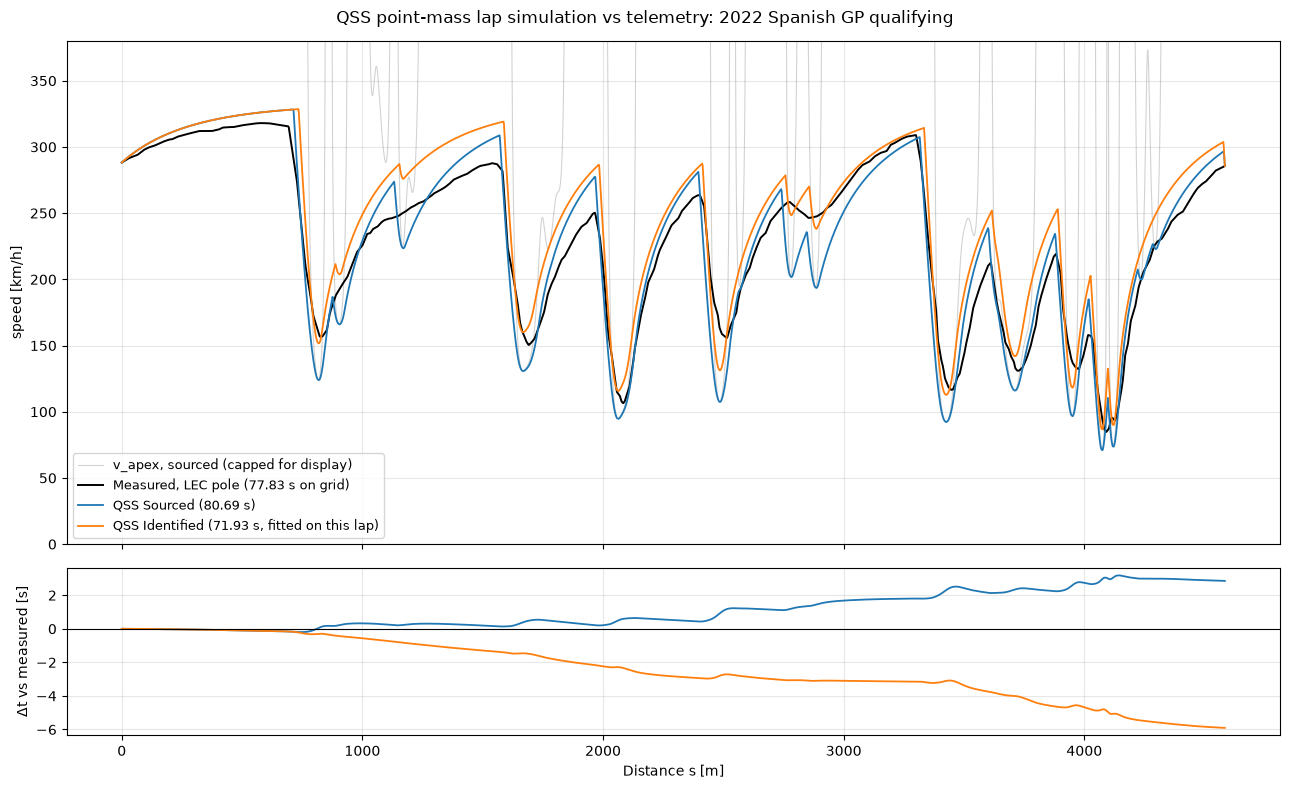

In [16]:
# =================================
# Figure
# =================================

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})

ax1.plot(s, np.minimum(results['Sourced']['v_apex'], 400/3.6) * 3.6,
         color='grey', lw=0.8, alpha=0.35, label='v_apex, sourced (capped for display)')
ax1.plot(s, geo['v'] * 3.6, color='k', lw=1.4,
         label=f'Measured, LEC pole ({t_meas_grid:.2f} s on grid)')
for name, res in results.items():
    tag = ', fitted on this lap' if name == 'Identified' else ''
    ax1.plot(s, res['v'] * 3.6, lw=1.3, label=f"QSS {name} ({res['t']:.2f} s{tag})")
ax1.set_ylim(0, 380)
ax1.set_ylabel('speed [km/h]')
ax1.grid(alpha=0.3); ax1.legend(loc='lower left', fontsize=9)

for name, res in results.items():
    ax2.plot(s, cum_time(res['v']) - t_meas, lw=1.3, label=name)
ax2.axhline(0, color='k', lw=0.8)
ax2.set_ylabel('Δt vs measured [s]')
ax2.set_xlabel('Distance s [m]')
ax2.grid(alpha=0.3)

fig.suptitle('QSS point-mass lap simulation vs telemetry: 2022 Spanish GP qualifying')
plt.tight_layout()
plt.savefig('../figures/04_simulated_vs_measured.png', dpi=200)
plt.show()

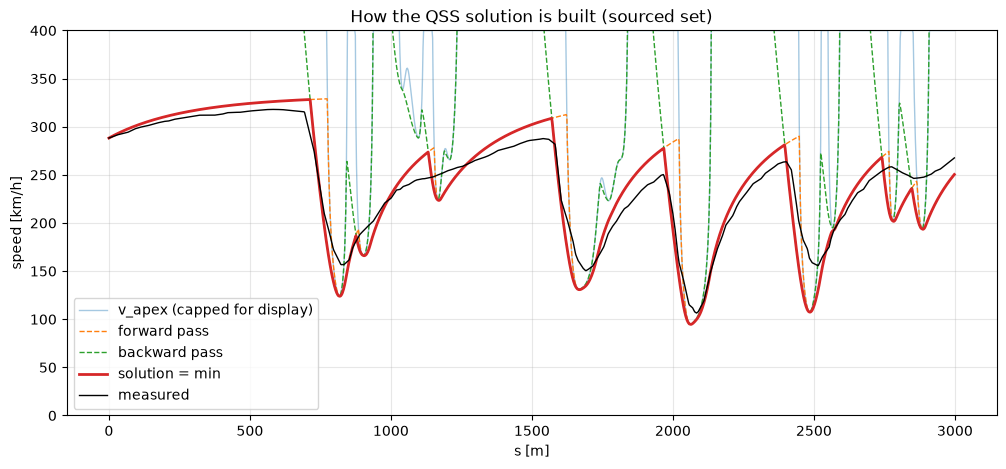

In [ ]:
# =================================
# Starting to find the brake point
# =================================

r = results['Sourced']
sl = slice(0, 1500)    # main straight into T1

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(geo['s'][sl], np.minimum(r['v_apex'][sl], 400/3.6) * 3.6, lw=1, alpha=0.4, label='v_apex (capped for display)')
ax.plot(geo['s'][sl], r['v_fwd'][sl] * 3.6, lw=1, ls='--', label='forward pass')
ax.plot(geo['s'][sl], r['v_bwd'][sl] * 3.6, lw=1, ls='--', label='backward pass')
ax.plot(geo['s'][sl], r['v'][sl] * 3.6, lw=2, label='solution = min')
ax.plot(geo['s'][sl], geo['v'][sl] * 3.6, lw=1, color='k', label='measured')
ax.set_ylim(0, 400)
ax.set_xlabel('s [m]'); ax.set_ylabel('speed [km/h]')
ax.set_title('How the QSS solution is built (sourced set)')
ax.grid(alpha=0.3); ax.legend(loc='lower left')
plt.show()